In [25]:
import numpy as np
import pandas as pd

In [28]:
fname_data = "../data/CM/Natural_CM.csv"
fname_gen = "../data/CM/Generated_CM.csv"

df_data = pd.read_csv(fname_data)
df_gen = pd.read_csv(fname_gen)

## Logistic regression

In [31]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from adabmDCA.fasta import encode_sequence, get_tokens

tokens = get_tokens("protein")
X_train = np.eye(21)[encode_sequence(df_data["sequence"].values, tokens=tokens)].reshape(len(df_data), -1)
y_train = df_data["label"].values
X_test = np.eye(21)[encode_sequence(df_gen["sequence"].values, tokens=tokens)].reshape(len(df_gen), -1)
y_test = df_gen["label"].values

logreg = LogisticRegression(max_iter=1000)
logreg.fit(X_train, y_train)

y_pred = logreg.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy on generated data: {accuracy * 100:.2f}%")

Accuracy on generated data: 78.36%


## Analyze the RBM model

In [33]:
import torch
from annadca import annaRBMcat
from annadca.dataset import annaDataset
from annadca.utils import get_eigenvalues_history
from annadca.plot import plot_PCA
from adabmDCA.fasta import get_tokens

fname_data = "../data/CM/Natural_CM.csv"
fname_gen = "../data/CM/Generated_CM.csv"
fname_model = "../models/CM_params.h5"
fname_chains = "../models/CM_chains.fasta"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
dtype = torch.float32

# Import dataset
tokens = get_tokens("protein")
dataset = annaDataset(
    path_data=fname_data,
    column_names="header",
    column_sequences="sequence",
    column_labels="label",
    alphabet=tokens,
    device=device,
    dtype=dtype,
)

dataset_test = annaDataset(
    path_data=fname_gen,
    column_names="header",
    column_sequences="sequence",
    column_labels="label",
    alphabet=tokens,
    device=device,
    dtype=dtype,
)

data = dataset.data_one_hot
weights = dataset.weights.view(-1)
labels_data = dataset.to_label(dataset.labels_one_hot)

# Load the chains
rbm = annaRBMcat()
rbm.load(fname_model, device=device, dtype=dtype)
chains = rbm.load_chains(filename=fname_chains, alphabet=tokens, device=device, dtype=dtype)
labels_chains = dataset.to_label(chains["label"])

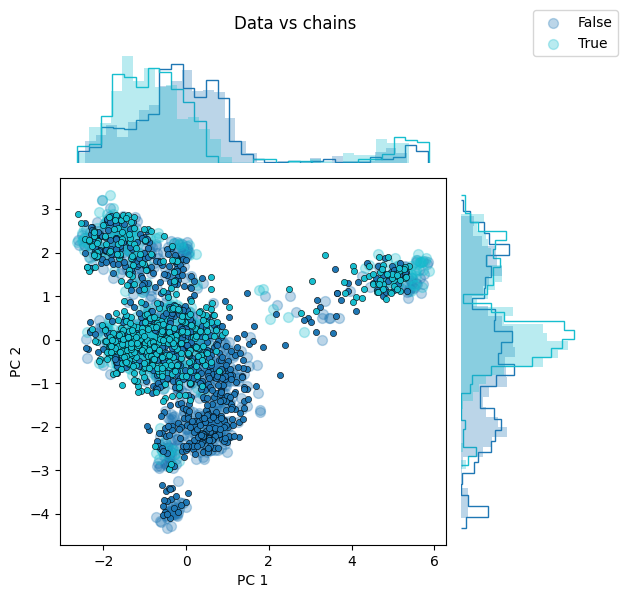

In [36]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# Project data and chains on the same PCA space
pca = PCA(n_components=2)
data_proj = pca.fit_transform(data.reshape(len(data), -1).cpu().numpy())
chains_proj = pca.transform(chains["visible"].view(len(chains["visible"]), -1).cpu().numpy())

# Define the colors
unique_labels = np.unique(labels_data)
cmap = plt.get_cmap("tab10", len(unique_labels))
label_to_color = {label.item(): cmap(i) for i, label in enumerate(unique_labels)}

fig = plt.figure(figsize=(6,6))
fig = plot_PCA(
    fig=fig,
    data1=data_proj,
    labels1=labels_data,
    data2=chains_proj,
    labels2=labels_chains,
    label_to_color=label_to_color,
    dim1=0,
    dim2=1,
    title="Data vs chains",
    split_labels=True,
)
fig.legend(bbox_to_anchor=(1.05, 1.0))
fig.tight_layout()

### Sample unconditioned

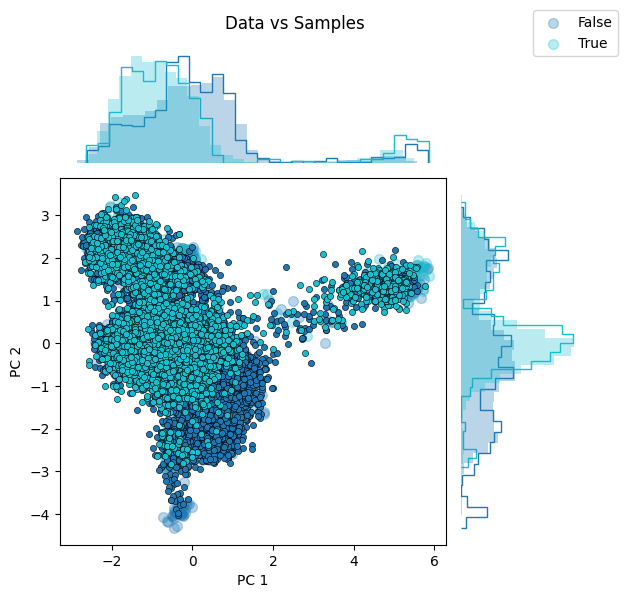

In [38]:
samples = rbm.sample(gibbs_steps=10000, num_samples=10000)
samples_proj = pca.transform(samples["visible"].view(len(samples["visible"]), -1).cpu().numpy())
samples_labels = dataset.to_label(samples["label"])

fig = plt.figure(figsize=(6,6))
fig = plot_PCA(
    fig=fig,
    data1=data_proj,
    labels1=labels_data,
    data2=samples_proj,
    labels2=samples_labels,
    label_to_color=label_to_color,
    dim1=0,
    dim2=1,
    title="Data vs Samples",
    split_labels=True,
)
fig.legend(bbox_to_anchor=(1.05, 1.0))
fig.tight_layout()

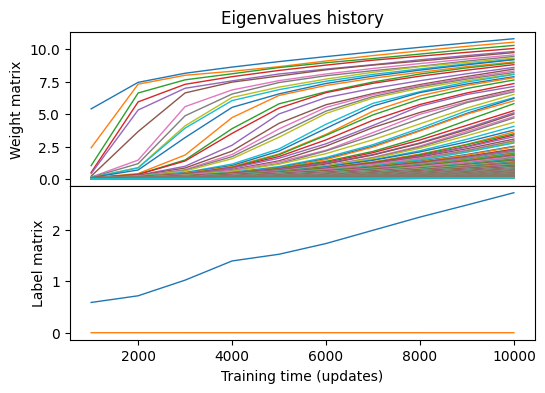

In [39]:
updates, eigenvalues = get_eigenvalues_history(fname_model, target_matrix="weight_matrix", device=device, dtype=dtype)
updates, eigenvalues_labels = get_eigenvalues_history(fname_model, target_matrix="label_matrix", device=device, dtype=dtype)

# Plot the eigenvalues history. first row is the weight matrix, second row is the label matrix.
fig, ax = plt.subplots(2, 1, figsize=(6, 4), sharex=True, gridspec_kw={'hspace': 0})
ax[0].plot(updates, eigenvalues, lw=1)
ax[1].plot(updates, eigenvalues_labels, lw=1)
ax[1].set_xlabel("Training time (updates)")
ax[0].set_ylabel("Weight matrix")
ax[1].set_ylabel("Label matrix")
ax[0].set_title("Eigenvalues history");

### Conditioned Sampling

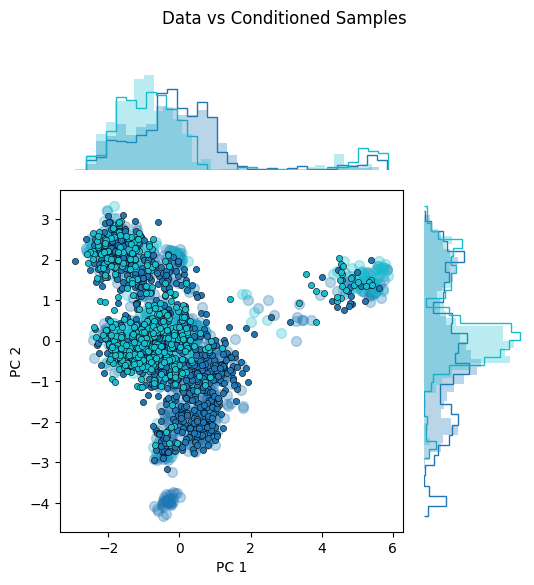

In [40]:
rbm.load(fname_model, device=device, dtype=dtype)
cond_chains = rbm.sample_conditioned(
    gibbs_steps=10000,
    targets=dataset.labels_one_hot,
)

cond_chains_proj = pca.transform(cond_chains["visible"].view(len(cond_chains["visible"]), -1).cpu().numpy())
cond_chains_labels = labels_data

fig = plt.figure(figsize=(6,6))
fig = plot_PCA(
    fig=fig,
    data1=data_proj,
    labels1=labels_data,
    data2=cond_chains_proj,
    labels2=cond_chains_labels,
    label_to_color=label_to_color,
    dim1=0,
    dim2=1,
    title="Data vs Conditioned Samples",
    split_labels=True,
)

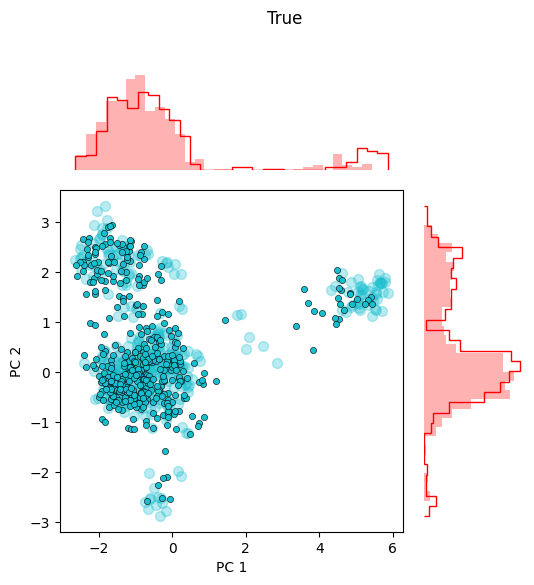

In [45]:
# Plot pca of conditioned chains and data but only one label
label_idx = 1
label = dataset.idx_to_label[label_idx]
mask_data = labels_data == label
mask_gen = cond_chains_labels == label
data_proj_label = data_proj[mask_data]
chains_proj_label = cond_chains_proj[mask_gen]

fig = plt.figure(figsize=(6,6))
fig = plot_PCA(
    fig=fig,
    data1=data_proj_label,
    labels1=labels_data[mask_data],
    data2=chains_proj_label,
    labels2=cond_chains_labels[mask_gen],
    label_to_color={label: cmap(label_idx)},
    dim1=0,
    dim2=1,
    title=label,
    split_labels=False,
)

In [44]:
# Train accuracy
predictions = rbm.predict_labels(visible=dataset.data_one_hot)
accuracy = (predictions.argmax(-1) == dataset.labels_one_hot.argmax(-1)).float().mean().item()
print(f"Train accuracy: {accuracy}")

predictions = rbm.predict_labels(visible=dataset_test.data_one_hot)
accuracy = (predictions.argmax(-1) == dataset_test.labels_one_hot.argmax(-1)).float().mean().item()
print(f"Test accuracy: {accuracy}")

Train accuracy: 0.8628318309783936
Test accuracy: 0.7896311283111572


In [46]:
from adabmDCA.stats import get_freq_single_point, get_freq_two_points, get_correlation_two_points

fi = get_freq_single_point(data=dataset.data_one_hot, weights=dataset.weights, pseudo_count=1e-8)
fij = get_freq_two_points(data=dataset.data_one_hot, weights=dataset.weights, pseudo_count=1e-8)
pi = get_freq_single_point(data=cond_chains["visible"], weights=None, pseudo_count=1e-8)
pij = get_freq_two_points(data=cond_chains["visible"], weights=None, pseudo_count=1e-8)

pearson, slope = get_correlation_two_points(fij, pij, fi, pi)
print(f"Pearson correlation: {pearson:.4f}, slope: {slope:.4f}")

Pearson correlation: 0.7800, slope: 0.6836
